In [11]:
from google.colab import drive
import os
import re
import json
import zipfile
import html
import pandas as pd
import numpy as np

# Mount Google Drive
drive.mount('/content/drive')

DRIVE_PROJECT_DIR = '/content/drive/MyDrive/Data Cleaning'

# Auto-detect folder location if placed in another directory
if not os.path.exists(DRIVE_PROJECT_DIR):
    print("Searching for project folder across Google Drive...")
    for root, dirs, files in os.walk('/content/drive/MyDrive'):
        if any('alpaca' in f.lower() for f in files):
            DRIVE_PROJECT_DIR = root
            print(f"✅ Found project folder at: {DRIVE_PROJECT_DIR}")
            break
else:
    print(f"✅ Drive mounted successfully! Working folder: {DRIVE_PROJECT_DIR}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Drive mounted successfully! Working folder: /content/drive/MyDrive/Data Cleaning


---
## 2: Configure Environment & Visualization Styles


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("✅ Visualization styling ready!")


✅ Visualization styling ready!


---
##  3: Define Text Cleaning & Categorization Logic


In [13]:
def clean_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = text.replace('\xa0', ' ').replace('\u200b', '').replace('\ufeff', '')
    text = html.unescape(text)
    text = re.sub(r'[ \t]+', ' ', text)
    return text.strip()

def detect_category(instruction: str, input_text: str, output: str) -> str:
    combined = f"{instruction} {input_text} {output}".lower()
    if any(k in combined for k in ['inflation', 'gdp', 'interest rate', 'central bank', 'monetary policy', 'fiscal policy', 'macroeconomic', 'unemployment rate', 'federal reserve']):
        return 'Macroeconomics & Monetary Policy'
    elif any(k in combined for k in ['stock', 'equity', 'dividend', 'nasdaq', 's&p', 'portfolio', 'bond', 'yield', 'etf', 'option', 'hedge fund', 'trading', 'brokerage', 'shareholder']):
        return 'Investments & Financial Markets'
    elif any(k in combined for k in ['balance sheet', 'ebitda', 'cash flow', 'depreciation', 'revenue', 'valuation', 'merger', 'acquisition', 'audit', 'p&l', 'accounting', 'financial statement']):
        return 'Corporate Finance & Accounting'
    elif any(k in combined for k in ['crypto', 'bitcoin', 'blockchain', 'ethereum', 'fintech', 'defi', 'digital currency', 'wallet']):
        return 'Crypto & FinTech'
    elif any(k in combined for k in ['tax', 'regulation', 'sec', 'compliance', 'irs', 'legal', 'deduction', 'w-2', '1099']):
        return 'Regulation, Tax & Compliance'
    elif any(k in combined for k in ['budget', 'savings', 'credit card', 'mortgage', 'loan', 'debt', 'personal finance', 'retirement', '401k', 'ira', 'bank account', 'emergency fund']):
        return 'Personal Finance & Banking'
    elif any(k in combined for k in ['finance', 'money', 'wealth', 'insurance', 'cost', 'price', 'fund', 'salary', 'income', 'expense', 'payment', 'pension', 'asset', 'liability']):
        return 'General Financial Advisory'
    else:
        return 'General Instruction / Miscellaneous'

def format_alpaca_prompt(instruction: str, input_text: str, output_text: str) -> str:
    if input_text:
        return (
            "Below is an instruction that describes a task, paired with an input that provides further context. "
            "Write a response that appropriately completes the request.\n\n"
            f"### Instruction:\n{instruction}\n\n### Input:\n{input_text}\n\n### Response:\n{output_text}"
        )
    else:
        return (
            "Below is an instruction that describes a task. Write a response that appropriately completes the request.\n\n"
            f"### Instruction:\n{instruction}\n\n### Response:\n{output_text}"
        )

def is_garbage_output(s: str) -> bool:
    s = s.strip()
    if not s or s.lower() in ['nan', 'null', 'none']:
        return True
    if len(s) < 2:
        return True
    if s.endswith(':') and len(s) <= 30:
        return True
    if s.lower() in ['source', 'good luck!']:
        return True
    return False

print("✅ Cleaning and formatting functions registered!")


✅ Cleaning and formatting functions registered!


---
##  4: Load, Clean & Enrich Finance-Alpaca


In [14]:
zip_candidates = [
    os.path.join(DRIVE_PROJECT_DIR, 'Raw Data', 'finance-alpaca-csv-20261013T105105Z-1-001.zip'),
    os.path.join(DRIVE_PROJECT_DIR, 'Cleaned Data', 'finance-alpaca-csv-20261013T105105Z-1-001.zip'),
    os.path.join(DRIVE_PROJECT_DIR, 'finance-alpaca-csv-20261013T105105Z-1-001.zip'),
    '/content/drive/MyDrive/finance-alpaca-csv-20261013T105105Z-1-001.zip',
    '/content/finance-alpaca-csv-20261013T105105Z-1-001.zip'
]

archive_path = None
for z in zip_candidates:
    if os.path.exists(z):
        archive_path = z
        break

try:
    if archive_path:
        print(f"0f2 Loading dataset directly from archive: {archive_path}")
        with zipfile.ZipFile(archive_path, 'r') as z_file:
            with z_file.open('finance-alpaca-csv/Cleaned_data.csv') as f:
                df_raw = pd.read_csv(f)
    else:
        # Check the correct folder 'Raw Data' where we verified 'Cleaned_data.csv' exists
        csv_fallback_candidates = [
            os.path.join(DRIVE_PROJECT_DIR, 'Raw Data', 'Cleaned_data.csv'),
            os.path.join(DRIVE_PROJECT_DIR, 'Cleaned Data', 'Cleaned_data.csv'),
            os.path.join(DRIVE_PROJECT_DIR, 'Cleaned_data.csv')
        ]
        csv_fallback = None
        for path in csv_fallback_candidates:
            if os.path.exists(path):
                csv_fallback = path
                break

        if csv_fallback is None:
            csv_fallback = csv_fallback_candidates[0]

        print(f"0f1 Loading uncompressed CSV: {csv_fallback}")
        df_raw = pd.read_csv(csv_fallback)
except FileNotFoundError as e:
    print(f"\n❌ Error: Could not find dataset files!")
    print(f"Current working directory contents: {os.listdir('.')}")
    if os.path.exists(DRIVE_PROJECT_DIR):
        print(f"Contents of {DRIVE_PROJECT_DIR}: {os.listdir(DRIVE_PROJECT_DIR)}")
        for folder in ['Cleaned Data', 'Raw Data']:
            subpath = os.path.join(DRIVE_PROJECT_DIR, folder)
            if os.path.exists(subpath):
                print(f"Contents of {subpath}: {os.listdir(subpath)}")
    else:
         print(f"Project directory does not exist: {DRIVE_PROJECT_DIR}")
    raise e

print(f"Raw shape: {df_raw.shape}")

cleaned_rows = []
seen_prompts = set()

for idx, row in df_raw.iterrows():
    raw_inst = row.get('instruction', '')
    raw_inp = row.get('input', '')
    raw_out = row.get('output', '')

    inst = clean_text(str(raw_inst) if pd.notnull(raw_inst) else '')
    inp = clean_text(str(raw_inp) if pd.notnull(raw_inp) and str(raw_inp).lower() != 'nan' else '')
    out = clean_text(str(raw_out) if pd.notnull(raw_out) and str(raw_out).lower() != 'nan' else '')

    if len(inst) < 3 or not out or is_garbage_output(out):
        continue

    inst_words = len(inst.split())
    inp_words = len(inp.split()) if inp else 0
    out_words = len(out.split())

    has_input = 1 if len(inp) > 0 else 0
    has_calc = 1 if any(sym in out for sym in ['```', '∑', '∫', 'sqrt(', '%', '$', '=']) else 0
    cat = detect_category(inst, inp, out)
    is_fin = 0 if cat == 'General Instruction / Miscellaneous' else 1

    prompt_key = (inst, inp)
    is_dup_prompt = prompt_key in seen_prompts
    seen_prompts.add(prompt_key)

    alpaca_text = format_alpaca_prompt(inst, inp, out)

    cleaned_rows.append({
        'id': len(cleaned_rows) + 1,
        'category': cat,
        'is_financial_domain': is_fin,
        'instruction': inst,
        'input': inp,
        'output': out,
        'text': alpaca_text,
        'instruction_word_count': inst_words,
        'input_word_count': inp_words,
        'output_word_count': out_words,
        'has_input': has_input,
        'has_calculation_or_code': has_calc,
        'is_prompt_duplicate': 1 if is_dup_prompt else 0
    })

df_clean = pd.DataFrame(cleaned_rows)
df_strictly_fin = df_clean[df_clean['is_financial_domain'] == 1].copy()

print(f"\n0f1 Total Cleaned Records: {len(df_clean):,}")
print(f"0f1 Specialized Financial Records: {len(df_strictly_fin):,} ({len(df_strictly_fin)/len(df_clean)*100:.1f}%)")
display(df_clean.head(3))

0f1 Loading uncompressed CSV: /content/drive/MyDrive/Data Cleaning/Raw Data/Cleaned_data.csv
Raw shape: (68912, 4)

0f1 Total Cleaned Records: 68,660
0f1 Specialized Financial Records: 26,900 (39.2%)


,id,category,is_financial_domain,instruction,input,output,text,instruction_word_count,input_word_count,output_word_count,has_input,has_calculation_or_code,is_prompt_duplicate
0,1,Macroeconomics & Monetary Policy,1,"For a car, what scams can be plotted with 0% f...",,The car deal makes money 3 ways. If you pay in...,Below is an instruction that describes a task....,13,0,371,0,1,0
1,2,Macroeconomics & Monetary Policy,1,Why does it matter if a Central Bank has a neg...,,"That is kind of the point, one of the hopes is...",Below is an instruction that describes a task....,16,0,72,0,0,0
2,3,"Regulation, Tax & Compliance",1,Where should I be investing my money?,,"Pay off your debt. As you witnessed, no ""inves...",Below is an instruction that describes a task....,7,0,69,0,1,0


---
##  5: Visualizations & Exploratory Analytics


/tmp/ipykernel_893/779652443.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_counts.values, y=cat_counts.index, palette='viridis')


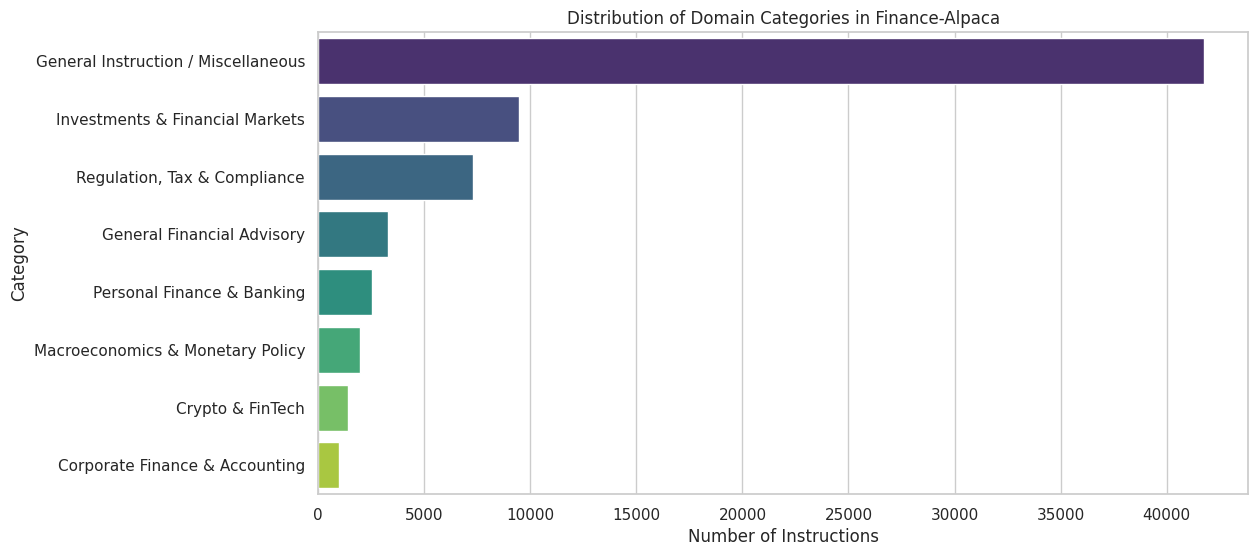

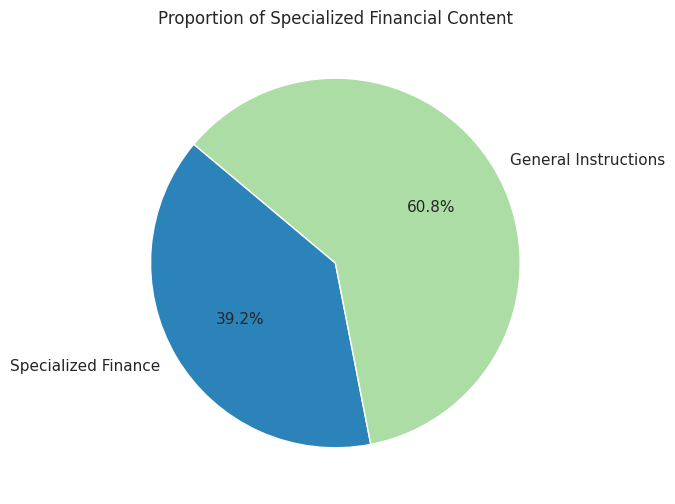

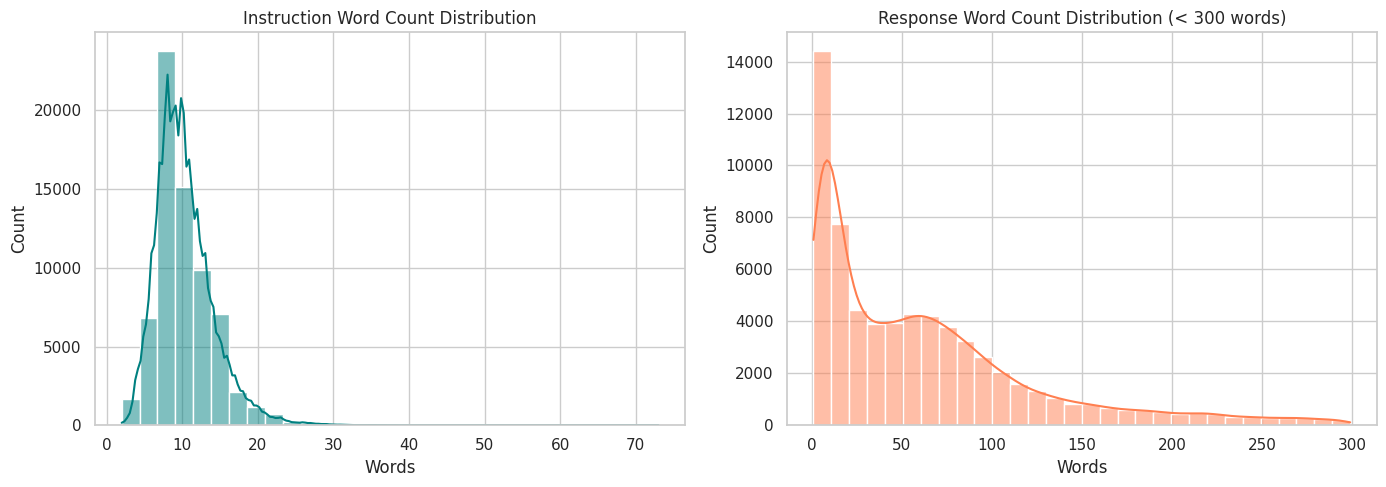

In [15]:
# 1. Domain Category Breakdown
plt.figure(figsize=(12, 6))
cat_counts = df_clean['category'].value_counts()
sns.barplot(x=cat_counts.values, y=cat_counts.index, palette='viridis')
plt.title("Distribution of Domain Categories in Finance-Alpaca")
plt.xlabel("Number of Instructions")
plt.ylabel("Category")
plt.show()

# 2. Financial vs General Proportion
plt.figure(figsize=(6, 6))
labels = ['Specialized Finance', 'General Instructions']
sizes = [df_clean['is_financial_domain'].sum(), len(df_clean) - df_clean['is_financial_domain'].sum()]
plt.pie(sizes, labels=labels, autopct='%1.1f%%', colors=['#2b83ba', '#abdda4'], startangle=140)
plt.title("Proportion of Specialized Financial Content")
plt.show()

# 3. Instruction & Response Word Lengths
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_clean['instruction_word_count'], bins=30, kde=True, color='teal', ax=axes[0])
axes[0].set_title("Instruction Word Count Distribution")
axes[0].set_xlabel("Words")

sns.histplot(df_clean[df_clean['output_word_count'] < 300]['output_word_count'], bins=30, kde=True, color='coral', ax=axes[1])
axes[1].set_title("Response Word Count Distribution (< 300 words)")
axes[1].set_xlabel("Words")
plt.tight_layout()
plt.show()


---
## 6: Export Cleaned Datasets back to Google Drive


In [16]:
csv_export_path = os.path.join(DRIVE_PROJECT_DIR, 'finance_alpaca_cleaned.csv')
fin_csv_export_path = os.path.join(DRIVE_PROJECT_DIR, 'finance_alpaca_strictly_financial_cleaned.csv')
jsonl_export_path = os.path.join(DRIVE_PROJECT_DIR, 'finance_alpaca_cleaned.jsonl')

df_clean.to_csv(csv_export_path, index=False, encoding='utf-8')
df_strictly_fin.to_csv(fin_csv_export_path, index=False, encoding='utf-8')

with open(jsonl_export_path, 'w', encoding='utf-8') as f:
    for _, r in df_clean.iterrows():
        record = {
            'id': r['id'],
            'instruction': r['instruction'],
            'input': r['input'],
            'output': r['output'],
            'category': r['category'],
            'text': r['text']
        }
        f.write(json.dumps(record, ensure_ascii=False) + '\n')

print("🎉 Successfully exported cleaned files to Google Drive:")
print(f"👉 {csv_export_path}")
print(f"👉 {fin_csv_export_path}")
print(f"👉 {jsonl_export_path}")


🎉 Successfully exported cleaned files to Google Drive:
👉 /content/drive/MyDrive/Data Cleaning/finance_alpaca_cleaned.csv
👉 /content/drive/MyDrive/Data Cleaning/finance_alpaca_strictly_financial_cleaned.csv
👉 /content/drive/MyDrive/Data Cleaning/finance_alpaca_cleaned.jsonl
